# 04 — Perceived authenticity in recipe reviews (Word2Vec + KWIC)

**Question:** *Do the recipes whose ingredients are most typical of their cuisine also get called "authentic" by the people who cook them?*

Simple word counting fails on recipe reviews because words like *authentic*, *traditional*, and *real* often appear in negations (*"not authentic"*), store-bought brands (*"Traditional Ragu"*), or generic praise (*"a real hit"*). 
That is why several methods were tested and evaluated. Here the best and simplest approach will be discussed.

A great reference has been a paper named "How consumers perceive authenticity in restaurants: A study of online reviews" by Le et al. (2022) which investigated a similar question of "authenticity" but in the context of restaurant reviews.

Our authenticity labelling can be subdivided in the following two simple steps:

1. **Word2Vec filtering**: Following Le et al., we use a vocabulary constructed via Word2Vec (also including the words already found by Le et al.) to filter all the reviews and keep candidate reviews mentioning both an authenticity term and a recipe attribute.
2. **Multi-rule KWIC**: classify authenticity endorsements with four KWIC checks per review filtered in 1.

We then performed some critical next steps:
-  **Validation**: evaluate precision and recall on 100 hand-labeled test reviews (`test_100.csv`).
-  **Network comparison**: join the authenticity labelled reviews with the ingredient-network and score the results, also run shuffle tests and confirm against an independent pure-embedding check.

at last we define our key findings and limitations of the process.


## 0. Setup and data

loading the data and a few simple numbers, as in the previous notebooks


In [1]:
from pathlib import Path
import html
import re
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from scipy.stats import spearmanr

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import authenticity as au

DATA = ROOT / "data" / "processed"
W2V_DIR = DATA / "recipe_word2vec"
SHARE_DIR = DATA / "authenticity_shareable"

plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})

recipes = pd.read_csv(DATA / "recipes.csv")
reviews = pd.read_csv(DATA / "reviews.csv")
network = pd.read_csv(DATA / "network_recipe_distinctiveness_full.csv")
print(f"Loaded {len(recipes):,} recipes, {len(reviews):,} reviews, and {len(network):,} network-scored recipes.")


Loaded 26,727 recipes, 132,744 reviews, and 26,727 network-scored recipes.


### 0.1 Counting

As a starting point (following the first notebook), we count how often the cleaned reviews contain *authentic* (including *authentically*, *authenticity*, *inauthentic*) and common synonyms (*traditional*, *original*, *real*, *genuine*), and plot *authentic* mentions per 1,000 reviews by cuisine.


,Term,Matching reviews,Share of reviews,Matching recipes
0,authentic*,1318,0.99%,913
1,traditional*,786,0.59%,647
2,original,771,0.58%,614
3,real,2103,1.58%,1481
4,genuine,25,0.02%,25


Reviews mentioning 'authentic*': 1,318 of 132,744 (0.99%), of which 99 contain explicit negation ('not authentic' / 'inauthentic').


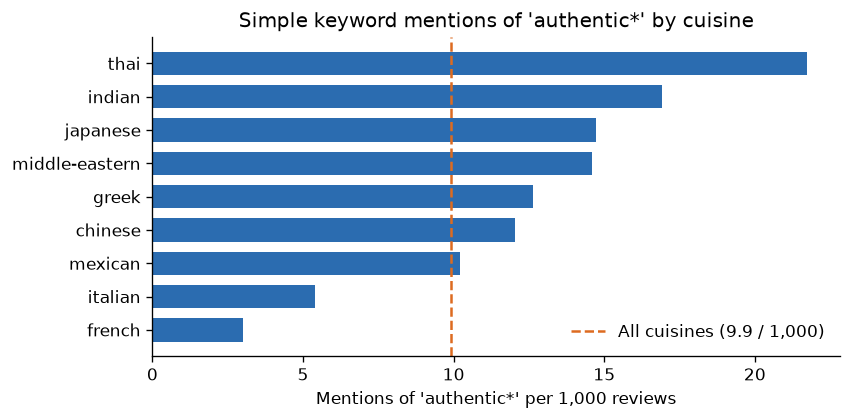

In [2]:
text_lower = reviews["review"].fillna("").map(html.unescape).str.lower()

# Count 'authentic*' and basic synonyms across all 132,744 cleaned reviews
syn_rows = []
for label, pat in [
    ("authentic*", r"\b(?:in)?authentic\w*"),
    ("traditional*", r"\btraditional\w*"),
    ("original", r"\boriginal\b"),
    ("real", r"\breal\b"),
    ("genuine", r"\bgenuine\b"),
]:
    hit = text_lower.str.contains(pat, regex=True)
    syn_rows.append({
        "Term": label,
        "Matching reviews": int(hit.sum()),
        "Share of reviews": f"{hit.mean():.2%}",
        "Matching recipes": int(reviews.loc[hit, "recipe_id"].nunique()),
    })
display(pd.DataFrame(syn_rows))

auth = text_lower.str.contains(r"\b(?:in)?authentic\w*", regex=True)
neg_auth = text_lower.loc[auth].str.contains(r"\b(?:not|isn'?t|wasn'?t|never|hardly)\s+(?:\w+\s+)?authentic|\binauthentic", regex=True).sum()
print(f"Reviews mentioning 'authentic*': {auth.sum():,} of {len(reviews):,} ({auth.mean():.2%}), of which {neg_auth:,} contain explicit negation ('not authentic' / 'inauthentic').")

# Rate per 1,000 reviews by cuisine (matching 01_initial_eda.ipynb)
by_c = (
    reviews.assign(auth=auth)
    .groupby("cuisine")["auth"]
    .agg(reviews="size", mentions="sum", per_1000=lambda s: s.mean() * 1000)
    .sort_values("per_1000")
)
fig, ax = plt.subplots(figsize=(7.2, 3.6))
ax.barh(by_c.index, by_c["per_1000"], color="#2b6cb0", height=0.7)
base = auth.mean() * 1000
ax.axvline(base, color="#dd6b20", ls="--", lw=1.5, label=f"All cuisines ({base:.1f} / 1,000)")
ax.set_xlabel("Mentions of 'authentic*' per 1,000 reviews")
ax.set_title("Simple keyword mentions of 'authentic*' by cuisine")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()


Simple keyword counting is not good enough because it treats every occurrence as an endorsement: counting explicit negations (*"not authentic"*), store-bought ingredient names (*"Traditional Ragu"*), and generic praise (*"a real hit"*) alongside genuine authenticity judgments. At the same time, searching only for *authentic* misses the many other words and recipe-specific phrases home cooks use to express authenticity, which motivates the Word2Vec vocabulary screen and clause-level KWIC rules next.


## 1. Word2Vec vocabulary filter

Following Le et al. (2022, §3.1), we trained skip-gram Word2Vec directly on all 132,744 cleaned Food.com reviews (608,802 sentences, 13,380 tokens with count ≥ 5; scripts/recipe_word2vec.py) to expand both Le et al.'s 88 authenticity seeds (top-10 nearest neighbors) and 6 starter recipe-attribute groups (dish, ingredient, preparation, sensory, origin, reference).





```python
from gensim.models import Word2Vec
from gensim.models.word2vec import LineSentence

model = Word2Vec(
    sentences=LineSentence(str(corpus)),
    vector_size=100, window=5, min_count=5,
    sg=1, negative=5, epochs=5, workers=1, seed=42,
)
neighbors = model.wv.most_similar(seed, topn=10)
```

Expanding both lists—just as Le et al. did for restaurant attributes—is necessary because a small hand-written seed list misses Food.com-specific variants, misspellings (like authenic), and regional dish or ingredient names (like biryani or tzatziki). After curating the learned neighbors into lexicon.csv, Word2Vec added 10 authenticity terms and 187 recipe-attribute words. Following Le et al. (§3.1), we then keep only reviews with at least one sentence containing both an authenticity term and a recipe attribute, anchoring broad seeds (real, true, careful) to the food rather than conversational filler (e.g., "a real hit with my kids"). 

It's important to note how applying this requirement of having both a recipe element and an authenticity term this is the first step to ensure the review is such that the authenticity is referred to the recipe being reviewd and not just including other recipes.

This narrows the corpus 18× to 7,281 candidate reviews (5.48%) across 4,295 recipes.


In [3]:
pd.set_option("display.max_colwidth", None)
lexicon = pd.read_csv(W2V_DIR / "lexicon.csv")
neighbors = pd.read_csv(W2V_DIR / "neighbors.csv")

# Table 1: Authenticity synonyms / variants added by Word2Vec
w2v_auth = set(lexicon.query("category == 'authenticity' and source == 'word2vec'")["token"])
auth_tbl = (
    neighbors.query("category == 'authenticity' and neighbor in @w2v_auth")
    .sort_values("cosine", ascending=False)
    .drop_duplicates("neighbor")[["neighbor", "seed", "cosine"]]
    .rename(columns={"neighbor": "Added term", "seed": "Nearest seed", "cosine": "Cosine similarity"})
    .assign(**{"Cosine similarity": lambda d: d["Cosine similarity"].round(3)})
    .reset_index(drop=True)
)
print("Table 1 — Authenticity synonyms / variants added by Word2Vec (10 terms):")
display(auth_tbl)

# Table 2: The 6 expanded recipe-attribute groups
attr_rows = []
for cat, grp in lexicon[lexicon["category"] != "authenticity"].groupby("category"):
    seeds = sorted(grp.query("source == 'seed'")["token"].tolist())
    added = sorted(grp.query("source == 'word2vec'")["token"].tolist())
    attr_rows.append({
        "Attribute group": cat,
        "Seed words": len(seeds),
        "Word2Vec added": len(added),
        "Example Word2Vec additions": ", ".join(added[:8]) + ("..." if len(added) > 8 else ""),
    })
print("\nTable 2 — Expanded recipe-attribute groups (6 groups, 187 terms added by Word2Vec):")
display(pd.DataFrame(attr_rows))

filtered = pd.read_csv(W2V_DIR / "dictionary_matched_full_reviews.csv")
print(f"\nStage-1 Word2Vec screen: {len(filtered):,} candidate reviews ({len(filtered)/len(reviews):.2%}) across {filtered['recipe_id'].nunique():,} recipes.")


Table 1 — Authenticity synonyms / variants added by Word2Vec (10 terms):


,Added term,Nearest seed,Cosine similarity
0,recreate,replicate,0.860
1,duplicate,replicate,0.849
2,speciality,specialty,0.837
3,homeade,home_made,0.832
4,reproduce,replicate,0.775
5,authentically,authentic,0.759
6,imitate,replicate,0.720
7,authenic,authentic,0.696
8,clone,classic,0.657
9,copycat,original,0.593



Table 2 — Expanded recipe-attribute groups (6 groups, 187 terms added by Word2Vec):


,Attribute group,Seed words,Word2Vec added,Example Word2Vec additions
0,dish,13,57,"bisque, breadsticks, bruschetta, burrito, burritos, casserole, chapati, chimichangas..."
1,ingredient,10,33,"basmati, beef, bulgur, cayenne, cheddar, cheeses, chickpeas, couscous..."
2,origin,17,37,"american, arabian, arabic, asian, balkan, basque, cantonese, caribbean..."
3,preparation,6,19,"broiling, browning, caramelizing, deglazing, dredging, folding, marination, methods..."
4,reference,5,23,"aunt, bakery, cafe, dad, father, grandfather, grandma, grandmas..."
5,sensory,4,18,"aftertaste, aromas, chewiness, consistency, creaminess, crispness, crunch, flavors..."



Stage-1 Word2Vec screen: 7,281 candidate reviews (5.48%) across 4,295 recipes.


**Reminder: to pass the Stage-1 Word2Vec filter, a sentence must contain at least one word from each table**—an **authenticity term** (the 88 Le et al. seeds + 10 Word2Vec additions in Table 1: *authentic, traditional, real, ..., authentically, authenic, ...*) **and** a **recipe attribute** (the 55 seeds + 187 Word2Vec additions across the 6 groups in Table 2: *dish, ingredient, origin, preparation, reference, sensory*).


In [4]:
# Three concrete examples illustrating what Stage 1 passes vs. rejects
test_ref = pd.read_csv(SHARE_DIR / "test_100.csv")
ex_pass_pos = test_ref[test_ref["manual_label"].astype(bool) & test_ref["full_review"].str.contains("authentic", case=False, na=False)].iloc[0]["full_review"]
ex_pass_neg = test_ref[~test_ref["manual_label"].astype(bool) & test_ref["full_review"].str.contains("Traditional|not the traditional", case=False, na=False)].iloc[0]["full_review"]
rejected = reviews[~reviews["review_id"].isin(set(filtered["review_id"]))]
ex_rejected = rejected[rejected["review"].str.contains(r"\breal hit\b", case=False, na=False)].iloc[0]["review"]

def clip(s, n=180):
    flat = " ".join(html.unescape(str(s)).split())
    return flat[:n] + ("..." if len(flat) > n else "")

print("\nThree concrete examples of the Stage-1 Word2Vec filter:")
display(pd.DataFrame([
    {"Outcome": "1. Passed & authentic endorsement", "Example review": clip(ex_pass_pos)},
    {"Outcome": "2. Passed, but NOT an endorsement", "Example review": clip(ex_pass_neg)},
    {"Outcome": "3. Rejected by Word2Vec filter", "Example review": clip(ex_rejected)},
]))



Three concrete examples of the Stage-1 Word2Vec filter:


,Outcome,Example review
0,1. Passed & authentic endorsement,Thank you for putting up an authentic recipe!
1,"2. Passed, but NOT an endorsement","Absolutely delicious! They were perfectly flavored and honestly, I did not have the time to make the homemade sauce, so I just simmered the meatballs in ""Traditional"" Ragu sauce an..."
2,3. Rejected by Word2Vec filter,I made these for my husbands birthday. They were a real hit. I did double the cabbage and used a little extra shrimp. Thanks for the recipe.


The next steps focus on filtering out the second kind of review—those that pass the Word2Vec screen without actually endorsing the recipe—which is hard because the exact same authenticity words appear in negations, store-bought ingredient names, suggested recipe edits, and comparisons to other dishes.


## 2. Clause-level KWIC rules

Le et al. (2022, Fig. 1) split authenticity into *Self* (atmosphere), *Producer* (service), and **Other** (*conformity*, *deviation*, *connection*). Since recipes only have ingredients and steps, we focus on **Other**: **Rules 1–3** capture those three cues, and **Rule 4** excludes home-cook recipe edits. A review is **endorsed** when **Rule 1 or 3** fires without **Rule 2 or 4**.


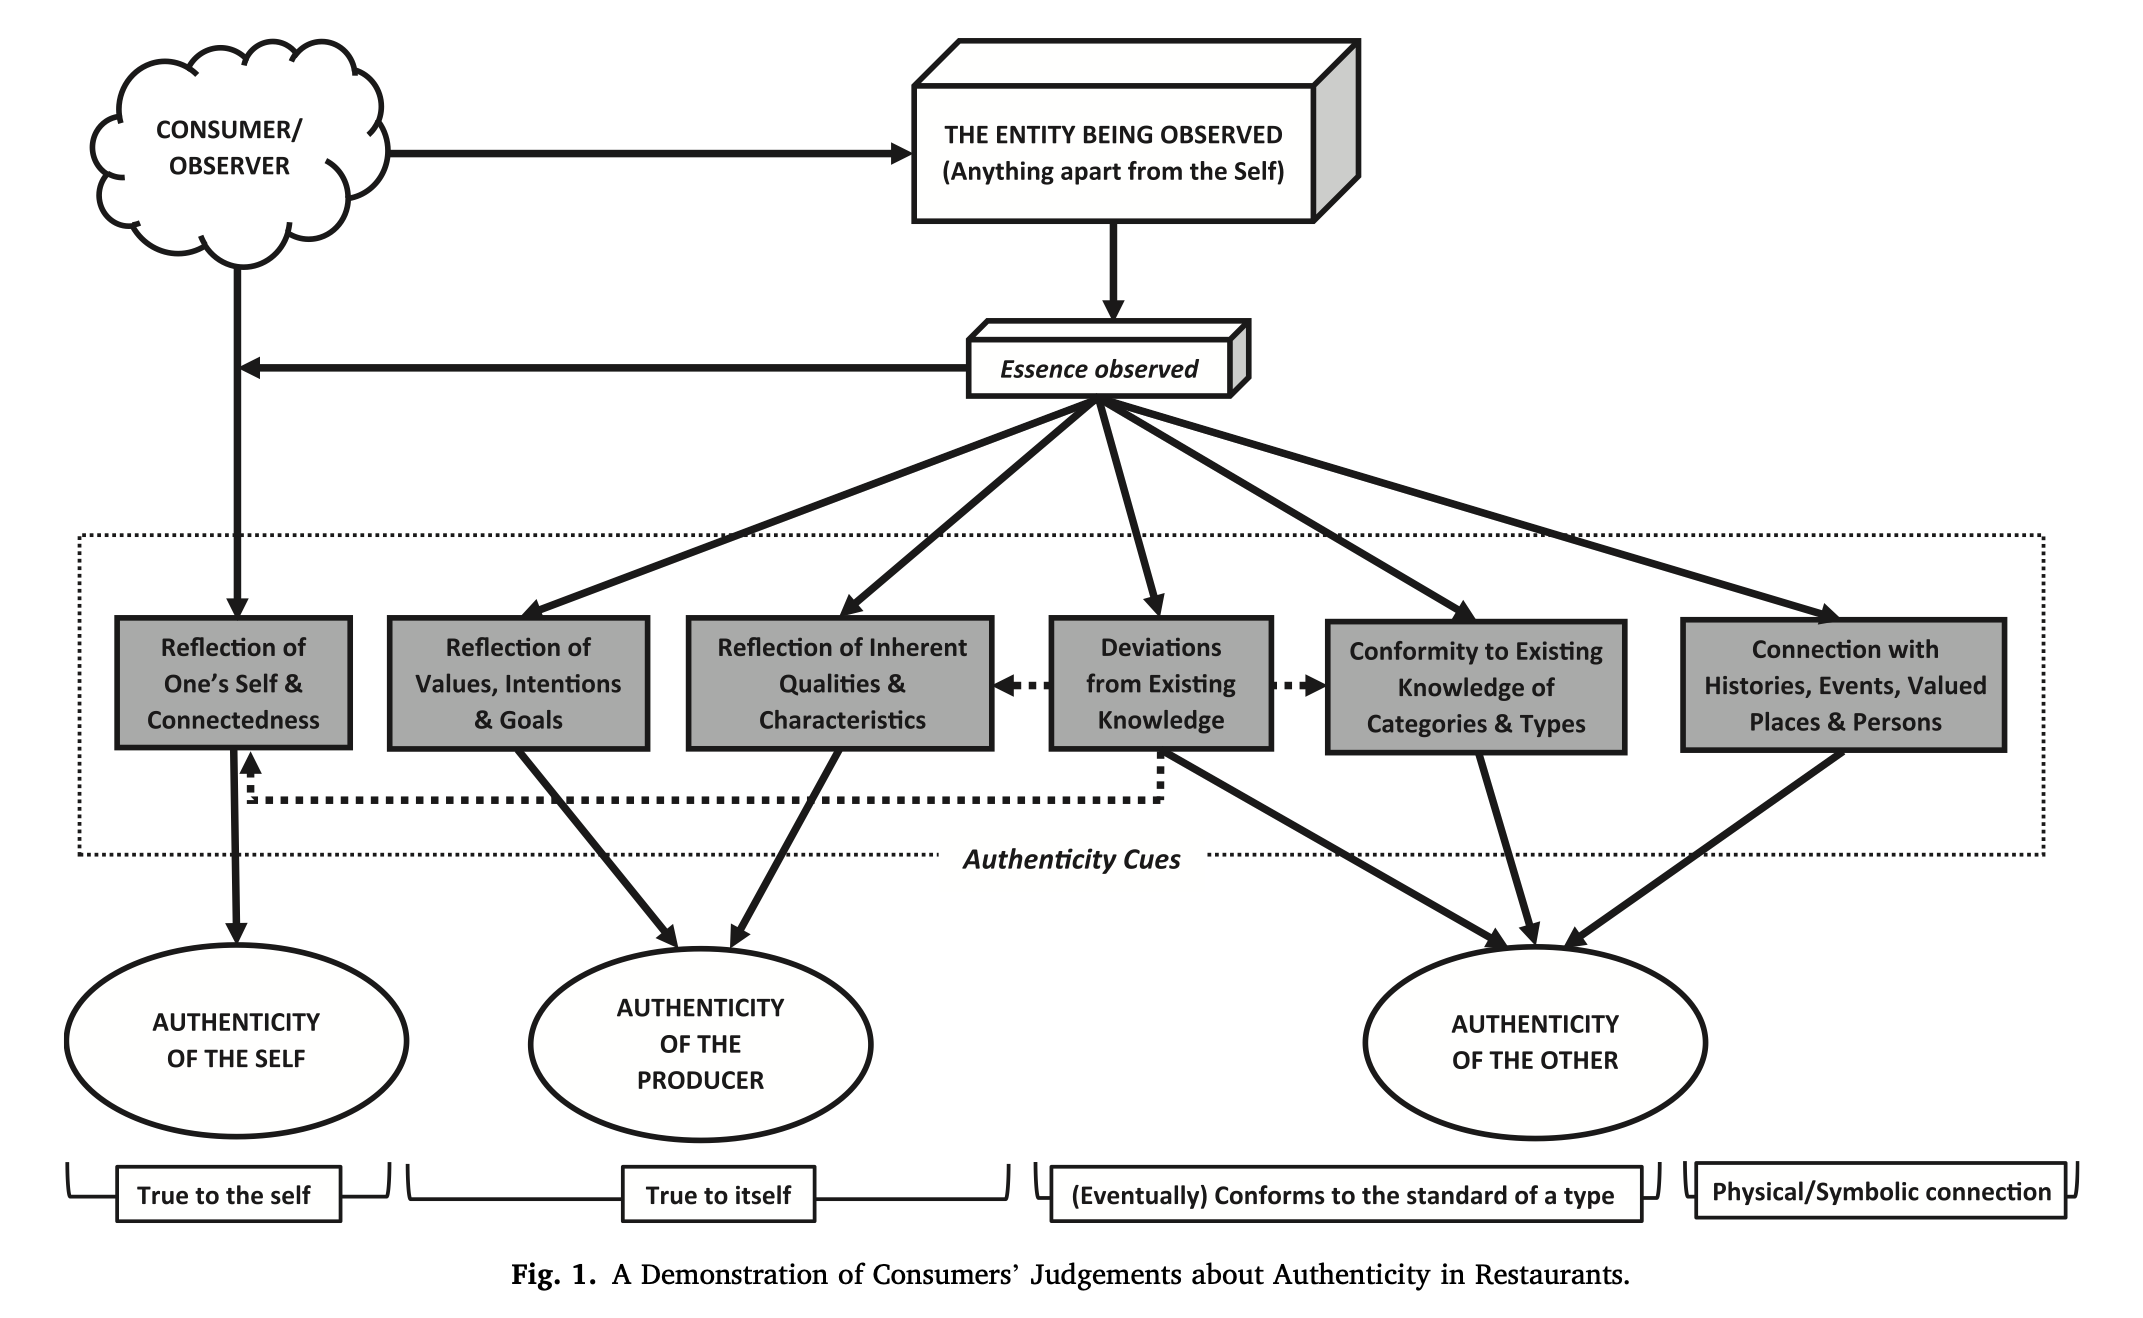

,Rule,Effect,What it matches (in a clause)
0,1. Conformity,Endorse,"authentic*, traditional*, genuine, real thing, real deal"
1,2. Deviation,Block,"Negation within 7 words before the cue (not, never, lacks, far from, n't)"
2,3. Connection,Endorse,"just like, reminds me of, tastes like / close to the original"
3,4. Recipe edits,Block,"more authentic, instead of, substitute, next time, would/could/should"



Sample KWIC concordances around 'authentic':


,Left context,Keyword,Right context
0,My,authentic,Mexican friend born in authentic Mexi
1,This recipe creates an,authentic,"Indian curry, which I was looking for"
2,", but, I assure you, this soup was so",authentic,"and satisfying, even with our flub up"
3,"ecipe, this sauce is great and tastes",authentic,". My husband likes them too, and reque"


In [5]:
display(Image(filename=str(ROOT / "figures/le2022_page8_themes.png"), width=700))

pd.set_option("display.max_colwidth", None)
rules_df = pd.DataFrame([
    {"Rule": "1. Conformity", "Effect": "Endorse", "What it matches (in a clause)": "authentic*, traditional*, genuine, real thing, real deal"},
    {"Rule": "2. Deviation", "Effect": "Block", "What it matches (in a clause)": "Negation within 7 words before the cue (not, never, lacks, far from, n't)"},
    {"Rule": "3. Connection", "Effect": "Endorse", "What it matches (in a clause)": "just like, reminds me of, tastes like / close to the original"},
    {"Rule": "4. Recipe edits", "Effect": "Block", "What it matches (in a clause)": "more authentic, instead of, substitute, next time, would/could/should"},
])
display(rules_df)

def kwic_sample(series, word="authentic", width=38, n=4, seed=7):
    pat = re.compile(rf"\b{word}\w*\b", re.I)
    rows = []
    for txt in series.sample(frac=1, random_state=seed):
        flat = " ".join(html.unescape(str(txt)).split())
        m = pat.search(flat)
        if m:
            rows.append({
                "Left context": flat[max(0, m.start() - width):m.start()].rjust(width),
                "Keyword": m.group(0),
                "Right context": flat[m.end():m.end() + width],
            })
            if len(rows) >= n:
                break
    return pd.DataFrame(rows)

print("\nSample KWIC concordances around 'authentic':")
display(kwic_sample(filtered["full_review"]))


## 3. Validation on hand-labeled reviews

We test our four KWIC rules on **100 hand-labeled reviews** (`test_100.csv`) and compare them against naive keyword matching (counting *authentic* or synonyms without negation or edit checks).


In [6]:
test_df = pd.read_csv(SHARE_DIR / "test_100.csv")[["recipe_id", "review_id", "full_review", "manual_label"]].copy()

def kwic_predict(texts):
    f = au.kwic_flags(texts)
    return (f[:, 0] == 1) | (f[:, 3] == 1)

def eval_metrics(name, y_true, y_pred):
    y, p = np.asarray(y_true, bool), np.asarray(y_pred, bool)
    tp, fp, fn, tn = int((y & p).sum()), int((~y & p).sum()), int((y & ~p).sum()), int((~y & ~p).sum())
    pr = tp / (tp + fp) if (tp + fp) else 0.0
    rc = tp / (tp + fn) if (tp + fn) else 0.0
    return {"Method (test_100)": name, "Reviews": len(y), "Labeled Endorsements": int(y.sum()),
            "True Positives": tp, "False Positives": fp, "False Negatives": fn, "True Negatives": tn,
            "Precision": round(pr, 3), "Recall": round(rc, 3)}

test_df["kwic_pred"] = kwic_predict(test_df["full_review"])
naive_test = test_df["full_review"].str.contains(r"\b(?:authentic\w*|traditional\w*|genuine|real|original)\b", case=False, regex=True)

display(pd.DataFrame([
    eval_metrics("KWIC rules (chosen: Rules 1-4)", test_df["manual_label"], test_df["kwic_pred"]),
    eval_metrics("Naive dictionary (no negation/clause rules)", test_df["manual_label"], naive_test),
]))

print("\nSample of held-out TEST reviews (3 positive, 3 negative):")
sample = pd.concat([
    test_df[test_df["manual_label"].astype(bool)].head(3),
    test_df[~test_df["manual_label"].astype(bool)].head(3),
])[["recipe_id", "manual_label", "kwic_pred", "full_review"]].copy()
sample["full_review"] = sample["full_review"].map(lambda s: " ".join(html.unescape(s).split())[:130] + "...")
display(sample)


,Method (test_100),Reviews,Labeled Endorsements,True Positives,False Positives,False Negatives,True Negatives,Precision,Recall
0,KWIC rules (chosen: Rules 1-4),100,22,16,3,6,75,0.842,0.727
1,Naive dictionary (no negation/clause rules),100,22,19,33,3,45,0.365,0.864



Sample of held-out TEST reviews (3 positive, 3 negative):


,recipe_id,manual_label,kwic_pred,full_review
0,166030,1,True,The perfect mixture for that traditional taco taste. No need to buy that packaged stuff. I used it for recipe #160564 and it was g...
1,47453,1,True,Thank you for putting up an authentic recipe!...
7,142306,1,True,This is an Authentic recipe that I and my husband use. We're from Michocan Mexico. But we prefer Queso Fresco crumbled on top with...
2,8745,0,False,wonderful I Dont' think i will ever make original enchiladas again. We are died in the wool Texans so everyone turned tier noses u...
3,31717,0,False,"I halved this recipe for my smaller crock pot. I also veganized it (using tvp for the ground beef and made my own veggie ""beefish""..."
4,88348,0,False,I made a vegetarian version of the soup by replacing the chicken with beans and a bit of chopped veggies. Even with the substituti...


### 3.1 Why 4 rules? (3 vs. 4 vs. 5 rules)

To test whether four rules is the right stopping point, we compare dropping Rule 4 (**3 rules**) and adding a broader 5th reference rule (**5 rules**: *restaurant, grandma, nonna, abuela, back home, grew up, way my*) on `test_100.csv`.


,Method (test_100),Reviews,Labeled Endorsements,True Positives,False Positives,False Negatives,True Negatives,Precision,Recall
0,test_100 | 3 rules (no Rule 4 edit filter),100,22,17,8,5,70,0.680,0.773
1,test_100 | 4 rules (chosen: Rules 1-4),100,22,16,3,6,75,0.842,0.727
2,test_100 | 5 rules (+ broad restaurant/family ref),100,22,18,5,4,73,0.783,0.818


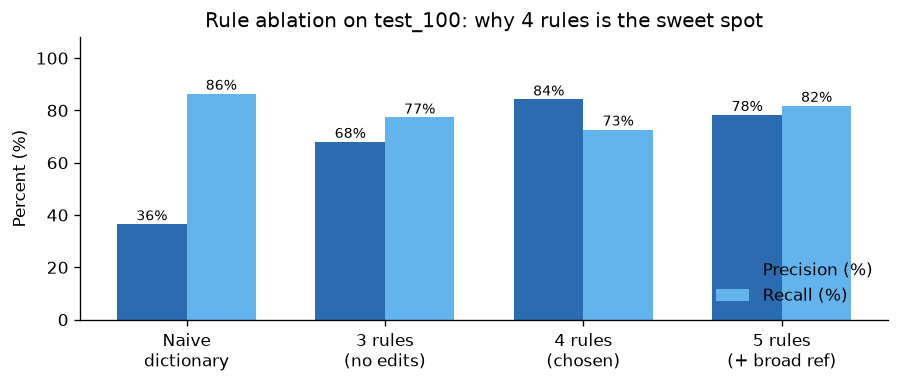

In [7]:
CUE = re.compile(r"\b(?:authentic\w*|traditional\w*|genuine|real thing|real deal)\b")
NEG = re.compile(r"\b(?:not|never|no|hardly|lacks?|lacked|without|anything but|far from)\b|n.t\b")
CHANGE = re.compile(r"\b(?:more authentic|instead of|substitut\w*|would|could|should|next time|to make it more)\b")
RESEMBLANCE = re.compile(r"\b(?:just like|exactly like|reminds me of|tastes? like the original|close to the original)\b")
BROAD_REF = re.compile(r"\b(?:restaurant|grandmother|grandma|nonna|abuela|back home|grew up|way my)\b")

def predict_3_4_5(texts):
    r3, r4, r5 = [], [], []
    for text in texts:
        t = html.unescape(str(text)).lower().replace("’", "'")
        f_no_mod = f_with_mod = f_resem = f_broad = False
        for clause in re.split(r"[.!?;]|\bbut\b", t):
            for cue in CUE.finditer(clause):
                before = " ".join(clause[:cue.start()].split()[-7:])
                neg = bool(NEG.search(before))
                chg = bool(CHANGE.search(clause))
                if not neg:
                    f_no_mod = True
                if not (neg or chg):
                    f_with_mod = True
            if RESEMBLANCE.search(clause) and not NEG.search(clause):
                f_resem = True
            if BROAD_REF.search(clause) and not NEG.search(clause):
                f_broad = True
        r3.append(f_no_mod or f_resem)
        r4.append(f_with_mod or f_resem)
        r5.append(f_with_mod or f_resem or f_broad)
    return np.array(r3), np.array(r4), np.array(r5)

rows_345 = []
for split_name, df_s in [("test_100", test_df)]:
    p3, p4, p5 = predict_3_4_5(df_s["full_review"])
    for lbl, p in [
        ("3 rules (no Rule 4 edit filter)", p3),
        ("4 rules (chosen: Rules 1-4)", p4),
        ("5 rules (+ broad restaurant/family ref)", p5),
    ]:
        rows_345.append(eval_metrics(f"{split_name} | {lbl}", df_s["manual_label"], p))

display(pd.DataFrame(rows_345))

# Visual comparison: Precision vs Recall across Naive, 3, 4 (chosen), and 5 rules on test_100
cmp_df = pd.DataFrame([
    eval_metrics("Naive\ndictionary", test_df["manual_label"], naive_test),
    eval_metrics("3 rules\n(no edits)", test_df["manual_label"], p3),
    eval_metrics("4 rules\n(chosen)", test_df["manual_label"], p4),
    eval_metrics("5 rules\n(+ broad ref)", test_df["manual_label"], p5),
])
x = np.arange(len(cmp_df))
w = 0.35
fig, ax = plt.subplots(figsize=(7.6, 3.3))
b1 = ax.bar(x - w/2, cmp_df["Precision"] * 100, width=w, color="#2b6cb0", label="Precision (%)")
b2 = ax.bar(x + w/2, cmp_df["Recall"] * 100, width=w, color="#63b3ed", label="Recall (%)")
for bars in (b1, b2):
    for bar in bars:
        v = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, v + 1.5, f"{v:.0f}%", ha="center", fontsize=8.5)
ax.set_xticks(x)
ax.set_xticklabels(cmp_df["Method (test_100)"])
ax.set_ylim(0, 108)
ax.set_ylabel("Percent (%)")
ax.set_title("Rule ablation on test_100: why 4 rules is the sweet spot")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()


**Takeaway:** Dropping Rule 4 (**3 rules**) more than doubles false positives (3 → 8), pulling precision down from **84.2% to 68.0%**. Adding a broader 5th rule (**5 rules**) also lowers precision (**84.2% → 78.3%**, +2 false positives) because words like *restaurant* and *grandma* often appear without judging authenticity. Four rules gives the cleanest precision while staying grounded in Le et al.'s cues plus recipe edits.


## 4. Scoring all 7,281 filtered reviews


In [8]:
filtered["kwic_endorsed"] = kwic_predict(filtered["full_review"])
n_pos_rev = int(filtered["kwic_endorsed"].sum())
n_pos_rec = int(filtered.loc[filtered["kwic_endorsed"], "recipe_id"].nunique())
n_tot_rec = int(filtered["recipe_id"].nunique())

print(f"Reviews classified: {len(filtered):,}")
print(f"  Endorsed reviews:     {n_pos_rev:,} ({n_pos_rev/len(filtered):.1%})")
print(f"  Non-endorsed reviews: {len(filtered) - n_pos_rev:,} ({1 - n_pos_rev/len(filtered):.1%})")
print(f"Recipes covered:    {n_tot_rec:,}")
print(f"  Endorsed recipes:     {n_pos_rec:,} ({n_pos_rec/n_tot_rec:.1%})")
print(f"  Non-endorsed recipes: {n_tot_rec - n_pos_rec:,} ({1 - n_pos_rec/n_tot_rec:.1%})")


Reviews classified: 7,281
  Endorsed reviews:     1,518 (20.8%)
  Non-endorsed reviews: 5,763 (79.2%)
Recipes covered:    4,295
  Endorsed recipes:     1,074 (25.0%)
  Non-endorsed recipes: 3,221 (75.0%)


## 5. Comparison with the ingredient network

We join recipe-level KWIC endorsements with the ingredient-network scores from `03_network_analysis.ipynb` (`network_recipe_distinctiveness_full.csv`):
- **`ingredient_distinctiveness` (*what*):** how typical the recipe's single ingredients are of its cuisine.
- **`pair_distinctiveness` (*which pairs*):** Ahn's raw pair score (mostly redundant with single ingredients, $r = 0.85$).
- **`pairing_score` (*how*):** whether its ingredient pairs co-occur more strongly than their separate popularity predicts (e.g., Italian *soffritto*, Indian *garlic + ginger*, Mexican *chili + cumin*).


### 5.1 Joining with ingredient-network scores (`pairing_score` quartiles and per-cuisine $\rho$)

Next, we join the recipe-level endorsements with `network_recipe_distinctiveness_full.csv`. Within each cuisine, we group recipes into quartiles of `pairing_score` (from lowest 25% to highest 25%) to see whether recipes with stronger ingredient combinations are endorsed more often, and compute the Spearman rank correlation $\rho$ separately for each of the nine cuisines.


,pairing_q,recipes,endorsed,endorsement_rate
0,Q1 (lowest 25%),1073,215,20.0%
1,Q2,1067,233,21.8%
2,Q3,1067,274,25.7%
3,Q4 (highest 25%),1068,348,32.6%


Top 10% vs Bottom 10% of pairing_score (KWIC): 18.3% -> 32.6% (1.78x)


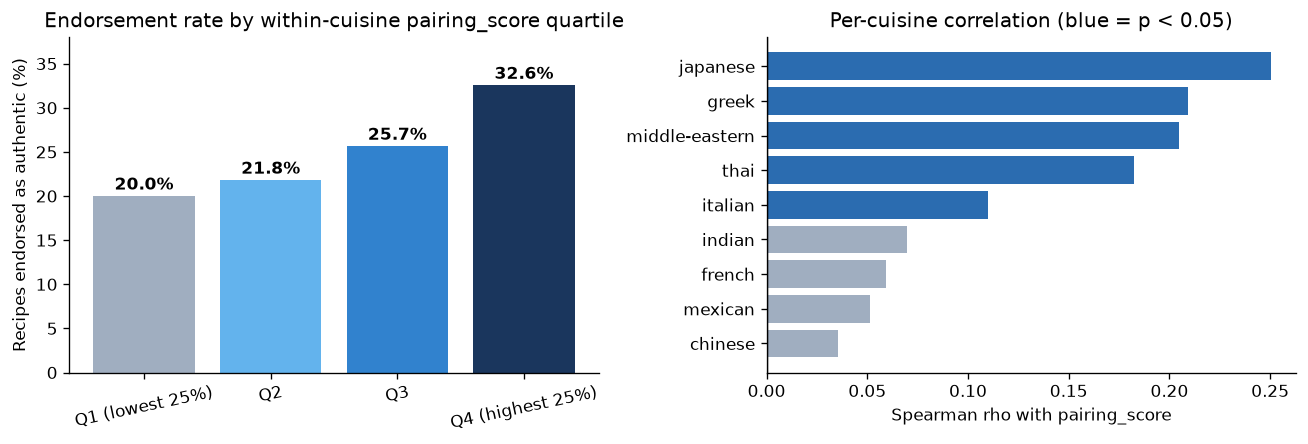

In [9]:
recipe_preds = filtered.groupby("recipe_id").agg(
    matched_reviews=("review_id", "size"),
    kwic_endorsed=("kwic_endorsed", "any"),
).reset_index()

m = (
    network.merge(recipe_preds, on="recipe_id", how="inner")
    .dropna(subset=["pairing_score"])
    .reset_index(drop=True)
)
m["y_kwic"] = m["kwic_endorsed"].astype(int)
m["pairing_q"] = m.groupby("cuisine")["pairing_score"].transform(
    lambda s: pd.qcut(s.rank(method="first"), 4, labels=["Q1 (lowest 25%)", "Q2", "Q3", "Q4 (highest 25%)"])
)
m["pairing_d"] = m.groupby("cuisine")["pairing_score"].transform(
    lambda s: pd.qcut(s.rank(method="first"), 10, labels=[f"D{i}" for i in range(1, 11)])
)

q_df = m.groupby("pairing_q", observed=False).agg(
    recipes=("recipe_id", "size"), endorsed=("y_kwic", "sum"), endorsement_rate=("y_kwic", "mean")
).reset_index()
display(q_df.assign(endorsement_rate=lambda d: d["endorsement_rate"].map("{:.1%}".format)))

d_kw = m.groupby("pairing_d", observed=False)["y_kwic"].mean()
print(f"Top 10% vs Bottom 10% of pairing_score (KWIC): {d_kw.iloc[0]:.1%} -> {d_kw.iloc[-1]:.1%} ({d_kw.iloc[-1]/d_kw.iloc[0]:.2f}x)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.0, 3.8))
ax1.bar(q_df["pairing_q"], q_df["endorsement_rate"] * 100, color=["#a0aec0", "#63b3ed", "#3182ce", "#1a365d"])
for i, v in enumerate(q_df["endorsement_rate"] * 100):
    ax1.text(i, v + 0.7, f"{v:.1f}%", ha="center", fontweight="bold")
ax1.set_ylim(0, 38)
ax1.set_ylabel("Recipes endorsed as authentic (%)")
ax1.set_title("Endorsement rate by within-cuisine pairing_score quartile")
ax1.tick_params(axis="x", rotation=12)

c_rows = []
for c, g in m.groupby("cuisine"):
    r, p = spearmanr(g["y_kwic"], g["pairing_score"])
    c_rows.append({"cuisine": c, "n": len(g), "endorsed": int(g["y_kwic"].sum()), "rho": r, "p": p})
c_df = pd.DataFrame(c_rows).sort_values("rho")
colors = ["#2b6cb0" if p < 0.05 else "#a0aec0" for p in c_df["p"]]
ax2.barh(c_df["cuisine"], c_df["rho"], color=colors)
ax2.axvline(0, color="black", linewidth=0.8)
ax2.set_xlabel("Spearman rho with pairing_score")
ax2.set_title("Per-cuisine correlation (blue = p < 0.05)")
plt.tight_layout()
plt.show()


**Reading the charts:** On the left, moving from the lowest 25% of `pairing_score` (Q1) to the highest 25% (Q4) lifts the share of endorsed recipes steadily from **20.0% to 32.6%** (and **1.78×** from bottom to top decile: 18.3% → 32.6%). On the right, all **9 of 9 cuisines** show a positive correlation, with **Japanese, Greek, Middle Eastern, Thai, and Italian** reaching $p < 0.05$ individually (blue bars).


### 5.2 Shuffle null tests and independent embedding check

To test whether these correlations could happen by chance—or simply because popular recipes receive more reviews—we shuffle the authenticity labels within each cuisine **2,000 times** and compare the observed Spearman $\rho$, **$z$-score**, and **empirical $p$-value** against the random null. The orange bars overlay an independent pure-embedding check (`scripts/pure_gte_check.py`, using `gte-small` with no keyword rules) to confirm the finding.


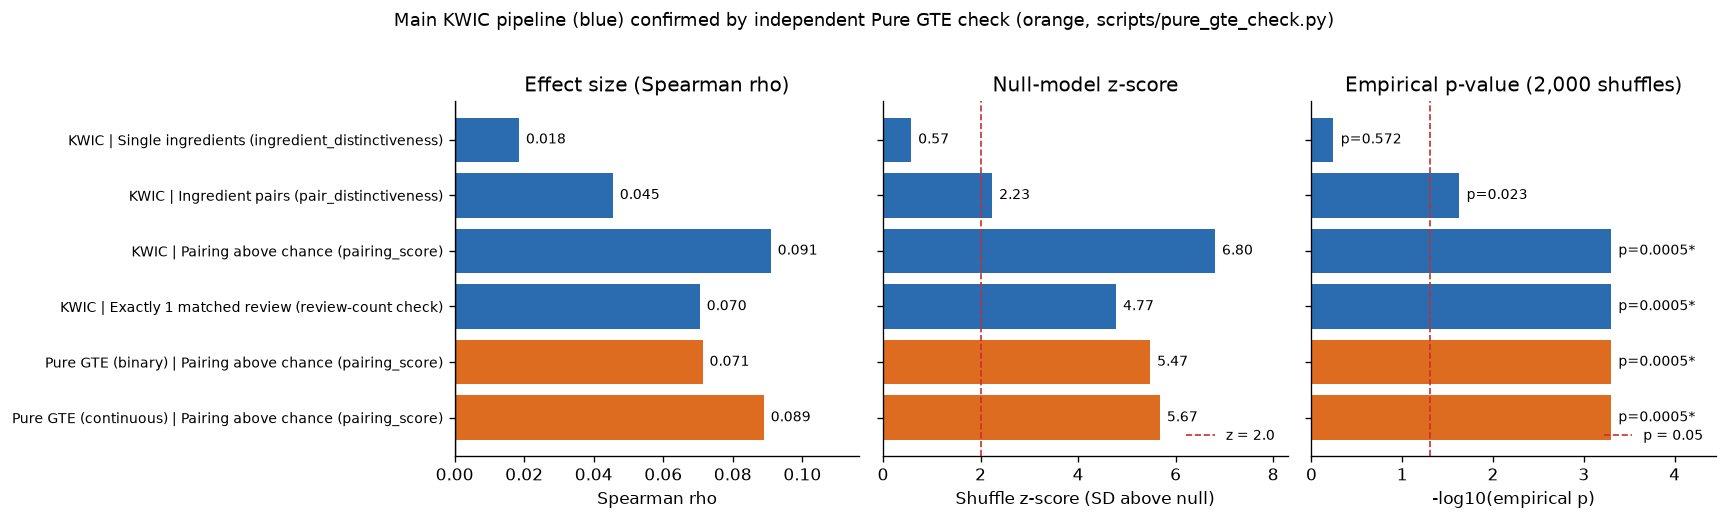

In [10]:
# Week 2 label-shuffle null tests (2,000 permutations) for KWIC + Pure GTE confirmation (scripts/pure_gte_check.py)
one_rev = m[m["matched_reviews"] == 1]

tests = [
    ("KWIC | Single ingredients (ingredient_distinctiveness)", m, "y_kwic", "ingredient_distinctiveness", ["cuisine"]),
    ("KWIC | Ingredient pairs (pair_distinctiveness)", m, "y_kwic", "pair_distinctiveness", ["cuisine"]),
    ("KWIC | Pairing above chance (pairing_score)", m, "y_kwic", "pairing_score", ["cuisine"]),
    ("KWIC | Exactly 1 matched review (review-count check)", one_rev, "y_kwic", "pairing_score", ["cuisine"]),
]
kwic_shuf = pd.DataFrame([{"test": lbl, **au.shuffle_test(sub, yc, xc, st, n_perm=2000, seed=42)} for lbl, sub, yc, xc, st in tests])
gte_shuf = pd.read_csv(W2V_DIR / "pure_gte_shuffle_summary.csv")
shuf_df = pd.concat([kwic_shuf, gte_shuf], ignore_index=True)

# 3-panel visual chart of Spearman rho, z-score, and empirical p-value (KWIC main + Pure GTE confirmation)
plot_df = shuf_df.iloc[::-1].reset_index(drop=True)
y_idx = np.arange(len(plot_df))
bar_colors = ["#dd6b20" if t.startswith("Pure GTE") else "#2b6cb0" for t in plot_df["test"]]

fig, (ax_r, ax_z, ax_p) = plt.subplots(1, 3, figsize=(14.5, 4.2), sharey=True)

ax_r.barh(y_idx, plot_df["obs_rho"], color=bar_colors)
ax_r.axvline(0, color="black", linewidth=0.8)
for i, v in enumerate(plot_df["obs_rho"]):
    ax_r.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=8.5)
ax_r.set_xlim(0, max(plot_df["obs_rho"]) * 1.28)
ax_r.set_yticks(y_idx)
ax_r.set_yticklabels(plot_df["test"], fontsize=8.5)
ax_r.set_xlabel("Spearman rho")
ax_r.set_title("Effect size (Spearman rho)")

ax_z.barh(y_idx, plot_df["z_score"], color=bar_colors)
ax_z.axvline(2.0, color="#c53030", linestyle="--", linewidth=1.0, label="z = 2.0")
for i, v in enumerate(plot_df["z_score"]):
    ax_z.text(v + 0.15, i, f"{v:.2f}", va="center", fontsize=8.5)
ax_z.set_xlim(0, max(plot_df["z_score"]) * 1.22)
ax_z.set_xlabel("Shuffle z-score (SD above null)")
ax_z.set_title("Null-model z-score")
ax_z.legend(frameon=False, loc="lower right", fontsize=8.5)

neg_log_p = -np.log10(plot_df["empirical_p"])
ax_p.barh(y_idx, neg_log_p, color=bar_colors)
ax_p.axvline(-np.log10(0.05), color="#c53030", linestyle="--", linewidth=1.0, label="p = 0.05")
for i, (nlp, pv) in enumerate(zip(neg_log_p, plot_df["empirical_p"])):
    lbl = "p=0.0005*" if pv <= 0.00051 else f"p={pv:.3f}"
    ax_p.text(nlp + 0.08, i, lbl, va="center", fontsize=8.5)
ax_p.set_xlim(0, max(neg_log_p) * 1.35)
ax_p.set_xlabel("-log10(empirical p)")
ax_p.set_title("Empirical p-value (2,000 shuffles)")
ax_p.legend(frameon=False, loc="lower right", fontsize=8.5)

fig.suptitle("Main KWIC pipeline (blue) confirmed by independent Pure GTE check (orange, scripts/pure_gte_check.py)", fontsize=10.5, y=1.02)
plt.tight_layout()
plt.show()


**Reading the chart:** Left shows the effect size ($\rho$), middle shows how many standard deviations the result sits above 2,000 random shuffles ($z$-score; dashed line at $z = 2$), and right shows statistical significance ($-\log_{10} p$; dashed line at $p = 0.05$). Single ingredients (`ingredient_distinctiveness`) sit inside random noise ($z = 0.57, p = 0.57$), whereas **`pairing_score`** sits far outside the null (**$z = 6.80, p = 0.0005$**) and survives both the 1-review control and the independent Pure GTE semantic check (orange bars, $z = 5.47\text{–}5.67$).


## 6. Considerations and conclusions

Across the **4,275 matched recipes**, listing cuisine-specific *single* ingredients (`ingredient_distinctiveness`) has almost no link with being called authentic, while characteristic ingredient *pairing* (`pairing_score`) shows a steady climb: endorsement rises from **20.0%** in the lowest quartile to **32.6%** in the highest quartile, and increases **1.78×** from the bottom decile to the top decile (**18.3% → 32.6%**). Because the overall rank correlation is modest ($\rho = 0.091$), the main doubt is whether this gap could be chance or a side effect of review volume.

Simple checks rule those doubts out. Shuffling authenticity labels within each cuisine 2,000 times never once reached the real `pairing_score` link (**$z = 6.80$, empirical $p = 0.0005$**), while single ingredients looked like chance ($z = 0.57, p = 0.57$). Restricting to the **3,214 recipes with exactly 1 matched review** (holding review count strictly constant) still reproduces a clear `pairing_score` signal (0 of 2,000 shuffles beat the data). Stopping at four KWIC rules could represent a local maximum among possible rule sets, but because it performs closely in line with our independent pure-embedding check (`scripts/pure_gte_check.py`, orange bars above: $\rho = 0.089$, $z = 5.67$, empirical $p = 0.0005$), we consider it good enough to answer the paper's question reliably without adding unnecessary complexity.

Our answer to the paper's question is therefore clear: **reviewers do not call a dish authentic just because it uses a cuisine's typical single ingredients (`ingredient_distinctiveness`, $\rho = 0.019$, $z = 0.57$); they call it authentic when it combines ingredients in the cuisine's typical way (`pairing_score`, $\rho = 0.091$, $z = 6.80$, empirical $p = 0.0005$)**. All nine cuisines lean positive—most strongly Japanese, Greek, Middle Eastern, Thai, and Italian. At the same time, the modest size of the correlation ($\rho \approx 0.09$) shows that an ingredient list alone can never capture everything people mean by "authentic." Two recipes can use the exact same ingredients yet turn out completely different depending on **cooking technique** (slow-simmering a sauce vs. rushing it) and **proportions** (a pinch of spice vs. an overpowering amount). Just as importantly, reviewers judge authenticity through **personal memories**—comparing a dish to a family recipe or a favorite local restaurant—and because **Food.com** is mostly a North American, English-speaking community, what reviewers call "authentic" often reflects familiar restaurant or diaspora versions rather than local culinary tradition.

## 7. Limitations and next steps

- **Stage-1 recall:** Purely implicit endorsements with no Word2Vec lexicon word (e.g., *"just like my grandmother made"*) sit outside the 7,281-review screen.
- **Explicit cues only:** Pure KWIC misses implicit endorsements inside the 7,281 reviews (72.7% recall on `test_100`) and occasionally flags store-bought brands (*"Traditional Ragu"*) or references to another recipe (84.2% precision).
- **Criticism vs. neutrality:** Explicit denials (*"not authentic"*) are grouped with neutral mentions rather than modeled as a separate negative class.
- **Platform bias:** Food.com (1999–2018) mostly reflects North American English-speaking home cooks, not local culinary tradition.
- **Next steps:** Double-coding a validation subset with two human annotators for inter-annotator agreement, and using an instruction-tuned **LLM** as a second-method check to capture implicit comparisons and separate denials from neutrality.
- **Word2Vec filter settings as a source of uncertainty:** Which words are pulled from Word2Vec (seed list, top-$k$ neighbor cutoff, and manual curation into `lexicon.csv`) directly determines which reviews enter the 7,281-review candidate pool, introducing an upstream source of uncertainty on top of the KWIC rules.
